# Fine-tune vs baseline rollout comparison (+15d)

Compare **same-catalog-window** rollout metrics at **+15 days** only:

| Source | Description |
|---|---|
| **Fine-tune** | Per-window models evaluated on their training window (`fineTuning/Test&Rollout/*__on__window_XX/`) |
| **Baseline** | Single pooled model evaluated per catalog window (`Test&Rollout/.../by_window/window_XX/`) |

Outputs: skill heatmap (center + full) and model RMSE loss bar plots. Only windows present in **both** result sets are included.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOK_DIR = Path.cwd().resolve()
SHALOW_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "fineTuning" else (
    NOTEBOOK_DIR if NOTEBOOK_DIR.name == "Shalow" else NOTEBOOK_DIR / "Shalow"
)

FINETUNE_ROLLOUT_DIR = SHALOW_DIR / "fineTuning" / "Test&Rollout"
BASELINE_BY_WINDOW_DIR = (
    SHALOW_DIR
    / "Test&Rollout"
    / "shalow_adv_no_uv_13_22_select_window_12_dt360_vgg_warm10_adv60_wd1e-3_drop0.1_select_window_12_l1random_slots6__on__select_window_12_test2023"
    / "by_window"
)
OUTPUT_DIR = NOTEBOOK_DIR if NOTEBOOK_DIR.name == "fineTuning" else SHALOW_DIR / "fineTuning"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

HORIZON_DAYS = 15
HORIZON_LABEL = f"+{HORIZON_DAYS}d"

BASELINE_LABEL = "Baseline (slots6)"
FINETUNE_LABEL = "Fine-tune (same window)"

print("Fine-tune rollout dir:", FINETUNE_ROLLOUT_DIR)
print("Baseline by-window dir:", BASELINE_BY_WINDOW_DIR)
print("Output dir:", OUTPUT_DIR)

Fine-tune rollout dir: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/fineTuning/Test&Rollout
Baseline by-window dir: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/Test&Rollout/shalow_adv_no_uv_13_22_select_window_12_dt360_vgg_warm10_adv60_wd1e-3_drop0.1_select_window_12_l1random_slots6__on__select_window_12_test2023/by_window
Output dir: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/fineTuning


In [2]:
_WINDOW_DIR_RE = re.compile(r"__on__window_(\d+)")


def _metric_at_horizon(metrics: list[dict], horizon_days: int, key: str) -> float:
    for row in metrics:
        if int(row["horizon_days"]) == int(horizon_days):
            return float(row[key])
    return float("nan")


def _short_catalog_key(export_key: str | None) -> str:
    if not export_key:
        return ""
    return export_key.replace("magicwin_", "")


def _row_label(window_number: int, catalog_key: str | None = None) -> str:
    short = _short_catalog_key(catalog_key)
    return f"W{window_number:02d}" + (f"\n{short}" if short else "")


def load_finetune_results(rollout_dir: Path) -> dict[int, dict]:
    out: dict[int, dict] = {}
    for results_path in sorted(rollout_dir.glob("*/rollout_results.json")):
        payload = json.loads(results_path.read_text())
        win = payload.get("finetune_window_number")
        if win is None:
            match = _WINDOW_DIR_RE.search(results_path.parent.name)
            if match is None:
                continue
            win = int(match.group(1))
        out[int(win)] = payload
    return out


def load_baseline_results(by_window_dir: Path) -> dict[int, dict]:
    out: dict[int, dict] = {}
    for results_path in sorted(by_window_dir.glob("window_*/rollout_results.json")):
        payload = json.loads(results_path.read_text())
        win = payload.get("window_number")
        if win is None:
            win = int(results_path.parent.name.split("_")[-1])
        out[int(win)] = payload
    return out


def build_comparison_table(
    finetune: dict[int, dict],
    baseline: dict[int, dict],
    *,
    horizon_days: int,
) -> pd.DataFrame:
    shared_windows = sorted(set(finetune) & set(baseline))
    if not shared_windows:
        raise FileNotFoundError(
            "No overlapping windows between fine-tune and baseline rollout results."
        )

    rows = []
    for win in shared_windows:
        ft = finetune[win]
        bl = baseline[win]
        catalog_key = ft.get("catalog_export_key") or bl.get("catalog_export_key")
        patch_sz = int(ft.get("speed_patch_size", bl.get("speed_patch_size", 4)))

        for region in ("center", "full"):
            metrics_key = f"metrics_{region}"
            bl_skill = _metric_at_horizon(bl[metrics_key], horizon_days, "skill_score")
            ft_skill = _metric_at_horizon(ft[metrics_key], horizon_days, "skill_score")
            bl_rmse = _metric_at_horizon(bl[metrics_key], horizon_days, "model_rmse")
            ft_rmse = _metric_at_horizon(ft[metrics_key], horizon_days, "model_rmse")
            persist_rmse = _metric_at_horizon(bl[metrics_key], horizon_days, "persistence_rmse")
            rows.append(
                {
                    "window_number": win,
                    "window_label": _row_label(win, catalog_key).replace("\n", " "),
                    "catalog_export_key": catalog_key,
                    "region": region,
                    "horizon_days": horizon_days,
                    "baseline_skill": bl_skill,
                    "finetune_skill": ft_skill,
                    "delta_skill": ft_skill - bl_skill,
                    "persistence_rmse": persist_rmse,
                    "baseline_model_rmse": bl_rmse,
                    "finetune_model_rmse": ft_rmse,
                    "delta_model_rmse": ft_rmse - bl_rmse,
                    "speed_patch_size": patch_sz,
                }
            )
    return pd.DataFrame(rows)


finetune_by_window = load_finetune_results(FINETUNE_ROLLOUT_DIR)
baseline_by_window = load_baseline_results(BASELINE_BY_WINDOW_DIR)
comparison_df = build_comparison_table(
    finetune_by_window,
    baseline_by_window,
    horizon_days=HORIZON_DAYS,
)

shared_windows = sorted(set(finetune_by_window) & set(baseline_by_window))
patch_sz = int(comparison_df["speed_patch_size"].iloc[0])
row_labels = [
    _row_label(
        win,
        finetune_by_window[win].get("catalog_export_key")
        or baseline_by_window[win].get("catalog_export_key"),
    )
    for win in shared_windows
]

print(f"Matched windows ({len(shared_windows)}):", ", ".join(f"W{w:02d}" for w in shared_windows))
print(f"Horizon: {HORIZON_LABEL} | speed patch: {patch_sz}×{patch_sz}")
display(comparison_df.pivot_table(
    index="window_label",
    columns="region",
    values=["baseline_skill", "finetune_skill", "delta_skill", "baseline_model_rmse", "finetune_model_rmse"],
))

Matched windows (12): W01, W02, W03, W04, W05, W06, W07, W08, W09, W10, W11, W12
Horizon: +15d | speed patch: 4×4


baseline_model_rmse           baseline_skill            \
region                           center      full         center      full   
window_label                                                                 
W01 reference                  0.226650  0.203735       0.404176  0.277213   
W02 coast_slide_n2             0.225897  0.211130       0.245488  0.184910   
W03 coast_slide_n1             0.310198  0.281873       0.320906  0.233993   
W04 coast_slide_s1             0.404360  0.257607       0.009803  0.124709   
W05 coast_slide_s2             0.261948  0.216527       0.260801  0.176325   
W06 bathy_mid                  0.195670  0.210943       0.382351  0.157972   
W07 bathy_east                 0.135916  0.144330       0.155852  0.119220   
W08 bathy_northeast            0.112083  0.161798       0.192944  0.134217   
W09 rot_0deg                   0.189341  0.199058       0.198221  0.225551   
W10 rot_23deg                  0.220557  0.234006       0.130430  0.110664   
W11 rot_45deg                  0.286991  0.262787       0.132093  0.220714   
W12 rot_68deg                  0.197980  0.203180       0.294601  0.254131   

                    delta_skill           finetune_model_rmse            \
region                   center      full              center      full   
window_label                                                              
W01 reference          0.014775  0.015647            0.221029  0.199325   
W02 coast_slide_n2     0.044734  0.017812            0.212504  0.206516   
W03 coast_slide_n1    -0.017664  0.009229            0.318267  0.278477   
W04 coast_slide_s1     0.090240  0.030564            0.367509  0.248612   
W05 coast_slide_s2     0.009304  0.029268            0.258651  0.208833   
W06 bathy_mid         -0.005751  0.004414            0.197492  0.209837   
W07 bathy_east        -0.016885 -0.000915            0.138635  0.144480   
W08 bathy_northeast   -0.058316 -0.009740            0.120182  0.163619   
W09 rot_0deg           0.038448  0.010302            0.180262  0.196410   
W10 rot_23deg          0.063602  0.030728            0.204425  0.225921   
W11 rot_45deg         -0.000111  0.008868            0.287028  0.259797   
W12 rot_68deg          0.025069  0.013924            0.190944  0.199387   

                    finetune_skill            
region                      center      full  
window_label                                  
W01 reference             0.418951  0.292861  
W02 coast_slide_n2        0.290223  0.202722  
W03 coast_slide_n1        0.303243  0.243223  
W04 coast_slide_s1        0.100043  0.155274  
W05 coast_slide_s2        0.270105  0.205594  
W06 bathy_mid             0.376600  0.162387  
W07 bathy_east            0.138967  0.118305  
W08 bathy_northeast       0.134628  0.124477  
W09 rot_0deg              0.236668  0.235853  
W10 rot_23deg             0.194033  0.141391  
W11 rot_45deg             0.131981  0.229582  
W12 rot_68deg             0.319670  0.268055

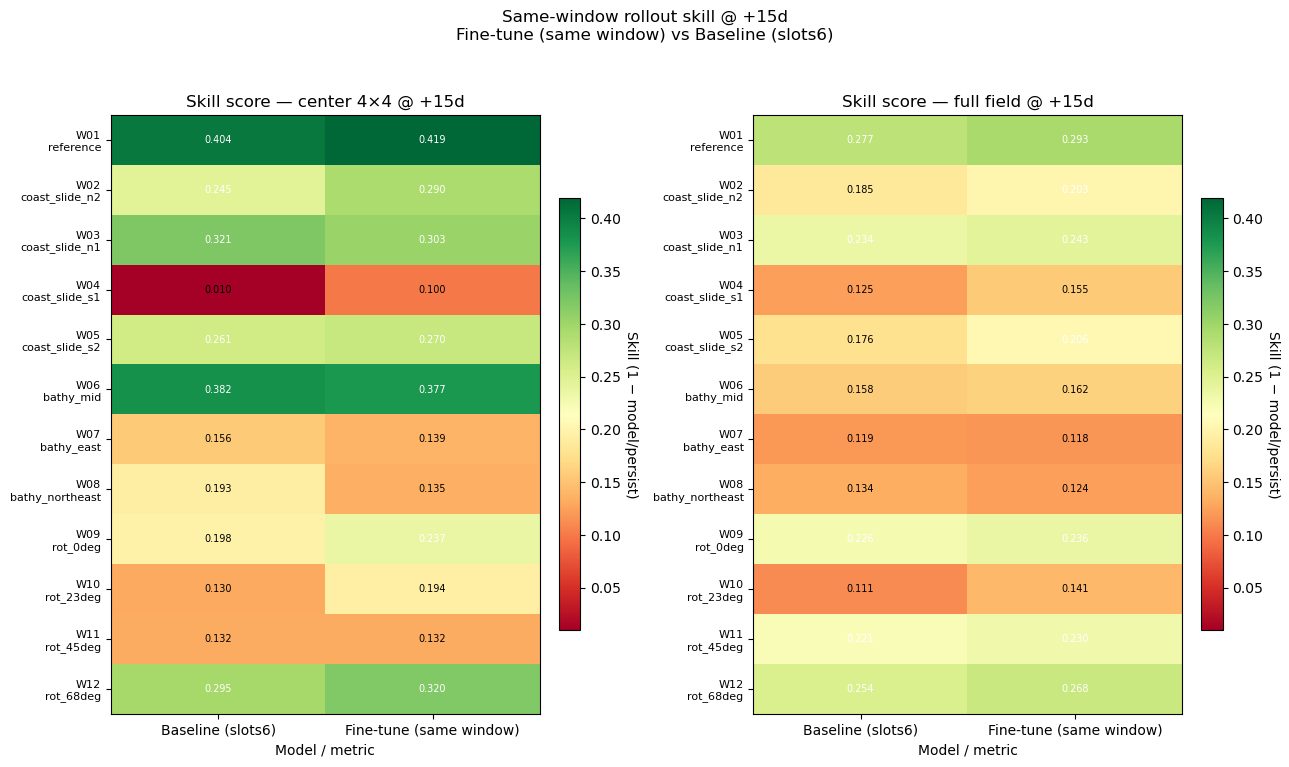

Saved: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/fineTuning/comparison_skill_heatmap_+15d.png


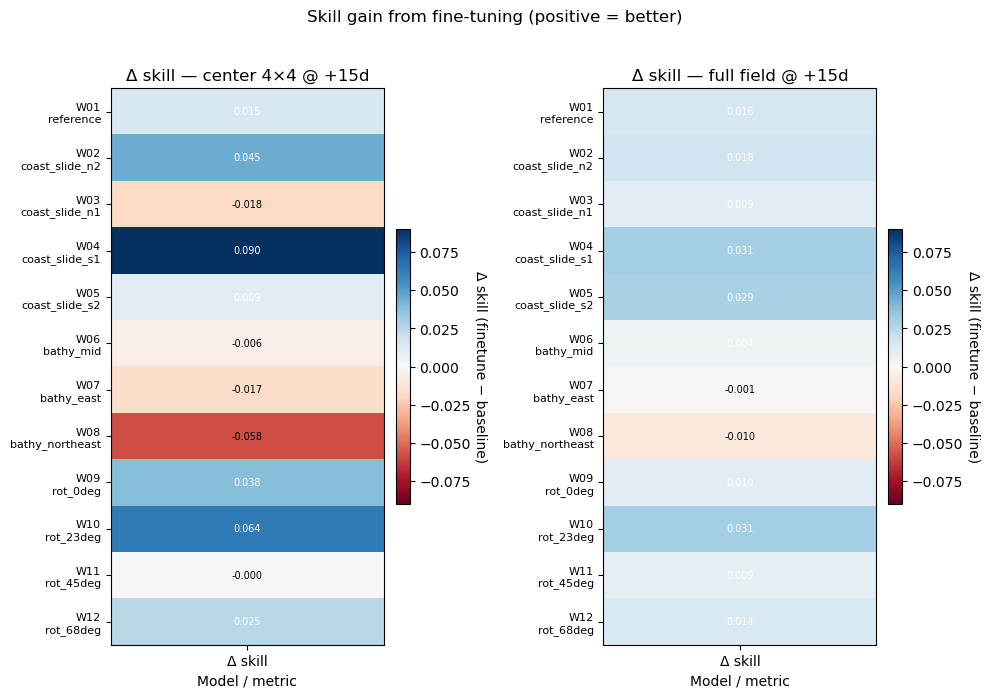

Saved: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/fineTuning/comparison_skill_delta_heatmap_+15d.png


In [3]:
def _plot_heatmap(
    ax,
    data: np.ndarray,
    row_labels: list[str],
    col_labels: list[str],
    *,
    title: str,
    cbar_label: str,
    cmap: str,
    vmin=None,
    vmax=None,
    fmt: str = ".3f",
    center_zero: bool = False,
):
    im = ax.imshow(data, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(np.arange(len(col_labels)))
    ax.set_xticklabels(col_labels)
    ax.set_yticks(np.arange(len(row_labels)))
    ax.set_yticklabels(row_labels, fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("Model / metric")
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(cbar_label, rotation=270, labelpad=12)

    if center_zero and vmax is not None and vmin is not None:
        mid = 0.5 * (float(vmax) + float(vmin))
    else:
        mid = float(np.nanmean(data))

    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            val = data[i, j]
            txt = "nan" if np.isnan(val) else format(val, fmt)
            ax.text(
                j,
                i,
                txt,
                ha="center",
                va="center",
                color="white" if val > mid else "black",
                fontsize=7,
            )


skill_cols = [BASELINE_LABEL, FINETUNE_LABEL]

skill_center = np.column_stack([
    comparison_df.query("region == 'center'").sort_values("window_number")["baseline_skill"].to_numpy(),
    comparison_df.query("region == 'center'").sort_values("window_number")["finetune_skill"].to_numpy(),
])
skill_full = np.column_stack([
    comparison_df.query("region == 'full'").sort_values("window_number")["baseline_skill"].to_numpy(),
    comparison_df.query("region == 'full'").sort_values("window_number")["finetune_skill"].to_numpy(),
])
skill_delta_center = comparison_df.query("region == 'center'").sort_values("window_number")["delta_skill"].to_numpy()[:, None]
skill_delta_full = comparison_df.query("region == 'full'").sort_values("window_number")["delta_skill"].to_numpy()[:, None]

skill_vmin = np.nanmin([skill_center, skill_full])
skill_vmax = np.nanmax([skill_center, skill_full])
delta_abs = np.nanmax(np.abs([skill_delta_center, skill_delta_full]))

fig, axes = plt.subplots(1, 2, figsize=(13, max(6, 0.45 * len(shared_windows) + 2)))

_plot_heatmap(
    axes[0],
    skill_center,
    row_labels,
    skill_cols,
    title=f"Skill score — center {patch_sz}×{patch_sz} @ {HORIZON_LABEL}",
    cbar_label="Skill (1 − model/persist)",
    cmap="RdYlGn",
    vmin=skill_vmin,
    vmax=skill_vmax,
)
_plot_heatmap(
    axes[1],
    skill_full,
    row_labels,
    skill_cols,
    title=f"Skill score — full field @ {HORIZON_LABEL}",
    cbar_label="Skill (1 − model/persist)",
    cmap="RdYlGn",
    vmin=skill_vmin,
    vmax=skill_vmax,
)

fig.suptitle(
    f"Same-window rollout skill @ {HORIZON_LABEL}\n"
    f"{FINETUNE_LABEL} vs {BASELINE_LABEL}",
    y=1.03,
    fontsize=12,
)
plt.tight_layout()
skill_path = OUTPUT_DIR / f"comparison_skill_heatmap_{HORIZON_LABEL}.png"
plt.savefig(skill_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {skill_path}")

fig_delta, axes_delta = plt.subplots(1, 2, figsize=(10, max(5, 0.4 * len(shared_windows) + 2)))
for ax, data, title in [
    (axes_delta[0], skill_delta_center, f"Δ skill — center {patch_sz}×{patch_sz}"),
    (axes_delta[1], skill_delta_full, "Δ skill — full field"),
]:
    _plot_heatmap(
        ax,
        data,
        row_labels,
        ["Δ skill"],
        title=f"{title} @ {HORIZON_LABEL}",
        cbar_label="Δ skill (finetune − baseline)",
        cmap="RdBu",
        vmin=-delta_abs,
        vmax=delta_abs,
        center_zero=True,
    )
fig_delta.suptitle("Skill gain from fine-tuning (positive = better)", y=1.02)
plt.tight_layout()
skill_delta_path = OUTPUT_DIR / f"comparison_skill_delta_heatmap_{HORIZON_LABEL}.png"
plt.savefig(skill_delta_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {skill_delta_path}")

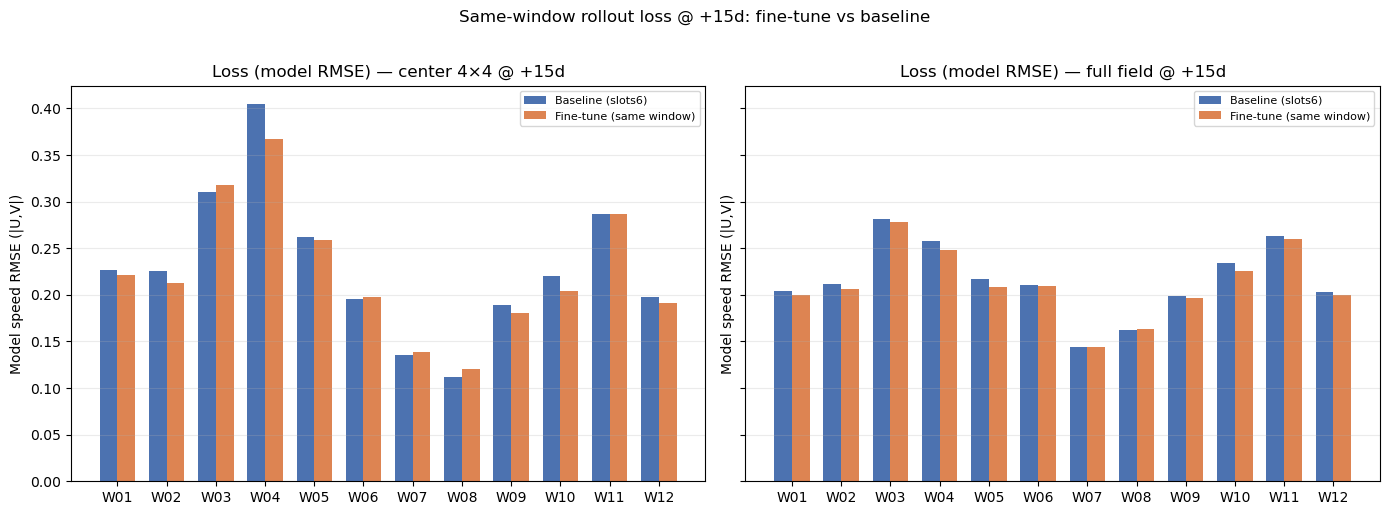

Saved: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/fineTuning/comparison_loss_barplot_+15d.png

Δ model RMSE @ +15d (center) — negative = fine-tune better:
  W01: baseline=0.2266  finetune=0.2210  Δ=-0.0056  Δskill=+0.0148
  W02: baseline=0.2259  finetune=0.2125  Δ=-0.0134  Δskill=+0.0447
  W03: baseline=0.3102  finetune=0.3183  Δ=+0.0081  Δskill=-0.0177
  W04: baseline=0.4044  finetune=0.3675  Δ=-0.0369  Δskill=+0.0902
  W05: baseline=0.2619  finetune=0.2587  Δ=-0.0033  Δskill=+0.0093
  W06: baseline=0.1957  finetune=0.1975  Δ=+0.0018  Δskill=-0.0058
  W07: baseline=0.1359  finetune=0.1386  Δ=+0.0027  Δskill=-0.0169
  W08: baseline=0.1121  finetune=0.1202  Δ=+0.0081  Δskill=-0.0583
  W09: baseline=0.1893  finetune=0.1803  Δ=-0.0091  Δskill=+0.0384
  W10: baseline=0.2206  finetune=0.2044  Δ=-0.0161  Δskill=+0.0636
  W11: baseline=0.2870  finetune=0.2870  Δ=+0.0000  Δskill=-0.0001
  W12: baseline=0.1980  finetune=0.1909  Δ=-0.0070  Δskill=+0.0251


In [4]:
PERSISTENCE_LABEL = "Persistence"

def _loss_bar_panel(ax, region: str, *, title: str):
    sub = comparison_df.query("region == @region").sort_values("window_number")
    x = np.arange(len(sub))
    width = 0.25

    ax.bar(
        x - width,
        sub["persistence_rmse"],
        width,
        label=PERSISTENCE_LABEL,
        color="#8C8C8C",
    )
    ax.bar(
        x,
        sub["baseline_model_rmse"],
        width,
        label=BASELINE_LABEL,
        color="#4C72B0",
    )
    ax.bar(
        x + width,
        sub["finetune_model_rmse"],
        width,
        label=FINETUNE_LABEL,
        color="#DD8452",
    )
    ax.set_xticks(x)
    ax.set_xticklabels([f"W{int(w):02d}" for w in sub["window_number"]], rotation=0)
    ax.set_ylabel("Speed RMSE (|U,V|)")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper right", fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
_loss_bar_panel(
    axes[0],
    "center",
    title=f"Loss (RMSE) — center {patch_sz}×{patch_sz} @ {HORIZON_LABEL}",
)
_loss_bar_panel(
    axes[1],
    "full",
    title=f"Loss (RMSE) — full field @ {HORIZON_LABEL}",
)
fig.suptitle(
    f"Same-window rollout loss @ {HORIZON_LABEL}: persistence vs baseline vs fine-tune",
    y=1.02,
    fontsize=12,
)
plt.tight_layout()
loss_path = OUTPUT_DIR / f"comparison_loss_barplot_{HORIZON_LABEL}.png"
plt.savefig(loss_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {loss_path}")

print(f"\nΔ model RMSE @ {HORIZON_LABEL} (center) — negative = fine-tune better:")
center_delta = comparison_df.query("region == 'center'").sort_values("window_number")
for _, row in center_delta.iterrows():
    print(
        f"  W{int(row['window_number']):02d}: "
        f"baseline={row['baseline_model_rmse']:.4f}  "
        f"finetune={row['finetune_model_rmse']:.4f}  "
        f"Δ={row['delta_model_rmse']:+.4f}  "
        f"Δskill={row['delta_skill']:+.4f}"
    )